<div style="display: flex; justify-content: flex-start; align-items: center;">
    <a href="https://colab.research.google.com/github/msfasha/307307-BI-Methods-Generative-AI/blob/main/20261/Module%201%20-%20What%20is%20an%20AI%20Agent/Module1_What_is_an_AI_Agent_lab.ipynb" target="_blank">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="height: 25px;">
    </a>
</div>

<div style="background:#F5EDF4; border-top:3px solid #A83296; padding:15px; border-radius:0 0 8px 8px">
<h1 style="color:#493347; margin:0">Lab — What Is an AI Agent? (Module 1)</h1>
<p style="color:#655263; margin:4px 0 0 0">Intro to Generative AI / Agentic AI — University of Petra</p>
</div>

**Course:** 307307 BI Methods for Generative AI (Agentic AI half)  
**Reference:** Grootendorst &amp; Alammar, *An Illustrated Guide to AI Agents* (O'Reilly, 2026), Chapter 1.

In this first lab you will build the **skeleton** of an agent from scratch (the `TinyAgent`), see that without a "brain" it does nothing useful, and then connect it to Google's **Gemini** model so it can actually answer. We build everything by hand, one small piece at a time, so you understand what an agent really is — not just how to call a library.

**What you will do:**
1. Build the `TinyAgent` skeleton and watch it simply echo your input.
2. Make your first call to the Gemini API (the "brain").
3. Wire the brain into the skeleton so the agent answers for real.
4. Reflect on what is still missing (memory, tools, planning) — the next modules.

> Don't worry if you have never written an API call before. Every step is explained, and the parts you fill in have a worked solution right below them.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Background (read first)</h2>
</div>

An **AI agent** is a reasoning LLM (the "brain") surrounded by **memory, tools, and planning**, working in a loop with a user and an environment. We will build that whole picture across the semester. Today we start with the bare skeleton.

The `TinyAgent` has three methods:
- `run(task)` — run the agent on a task (may take one step or many).
- `_step(task)` — do a single step (later: think, maybe call a tool).
- `_execute_action(action)` — carry out a tool action (added in a later module).

Right now these are **placeholders** — the agent has no brain yet.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 0 — Setup: your Gemini API key</h2>
</div>

We use the **Gemini API** through Google AI Studio — the same free setup described in your `Practical/` folder (`Howto create a gemini_api_key`).

1. Get a free API key at https://aistudio.google.com/apikey
2. Run the install cell, then the key cell (your key stays hidden and is **never** written into the notebook).

Never paste your key directly into a code cell or share it. Treat it like a password.

In [ ]:
# Install the Google Gemini SDK (and the OpenAI client, used later to show the 'from scratch' path).
# In Google Colab, remove the leading # to run this. Locally, run it once in your environment.
# %pip install -q google-genai openai

In [ ]:
import os
from getpass import getpass

# Prompt for the key only if it is not already set as an environment variable.
if not os.environ.get('GEMINI_API_KEY'):
    os.environ['GEMINI_API_KEY'] = getpass('Paste your Gemini API key (hidden): ')

# Choose a model that is ENABLED ON YOUR ACCOUNT.
# Your Practical/Google_AI_Studio lab uses 'gemini-3.8-flash'. If that is not available,
# try another current Gemini '*-flash' model listed in Google AI Studio.
MODEL = 'gemini-3.8-flash'
print('Key set:', bool(os.environ.get('GEMINI_API_KEY')), '| Model:', MODEL)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 1 — The TinyAgent skeleton (from scratch)</h2>
</div>

Let's write the smallest possible agent class. Notice it uses **no library and no LLM** — it is pure Python. The four attributes are placeholders for the pieces we add in later modules.

<div align="center">
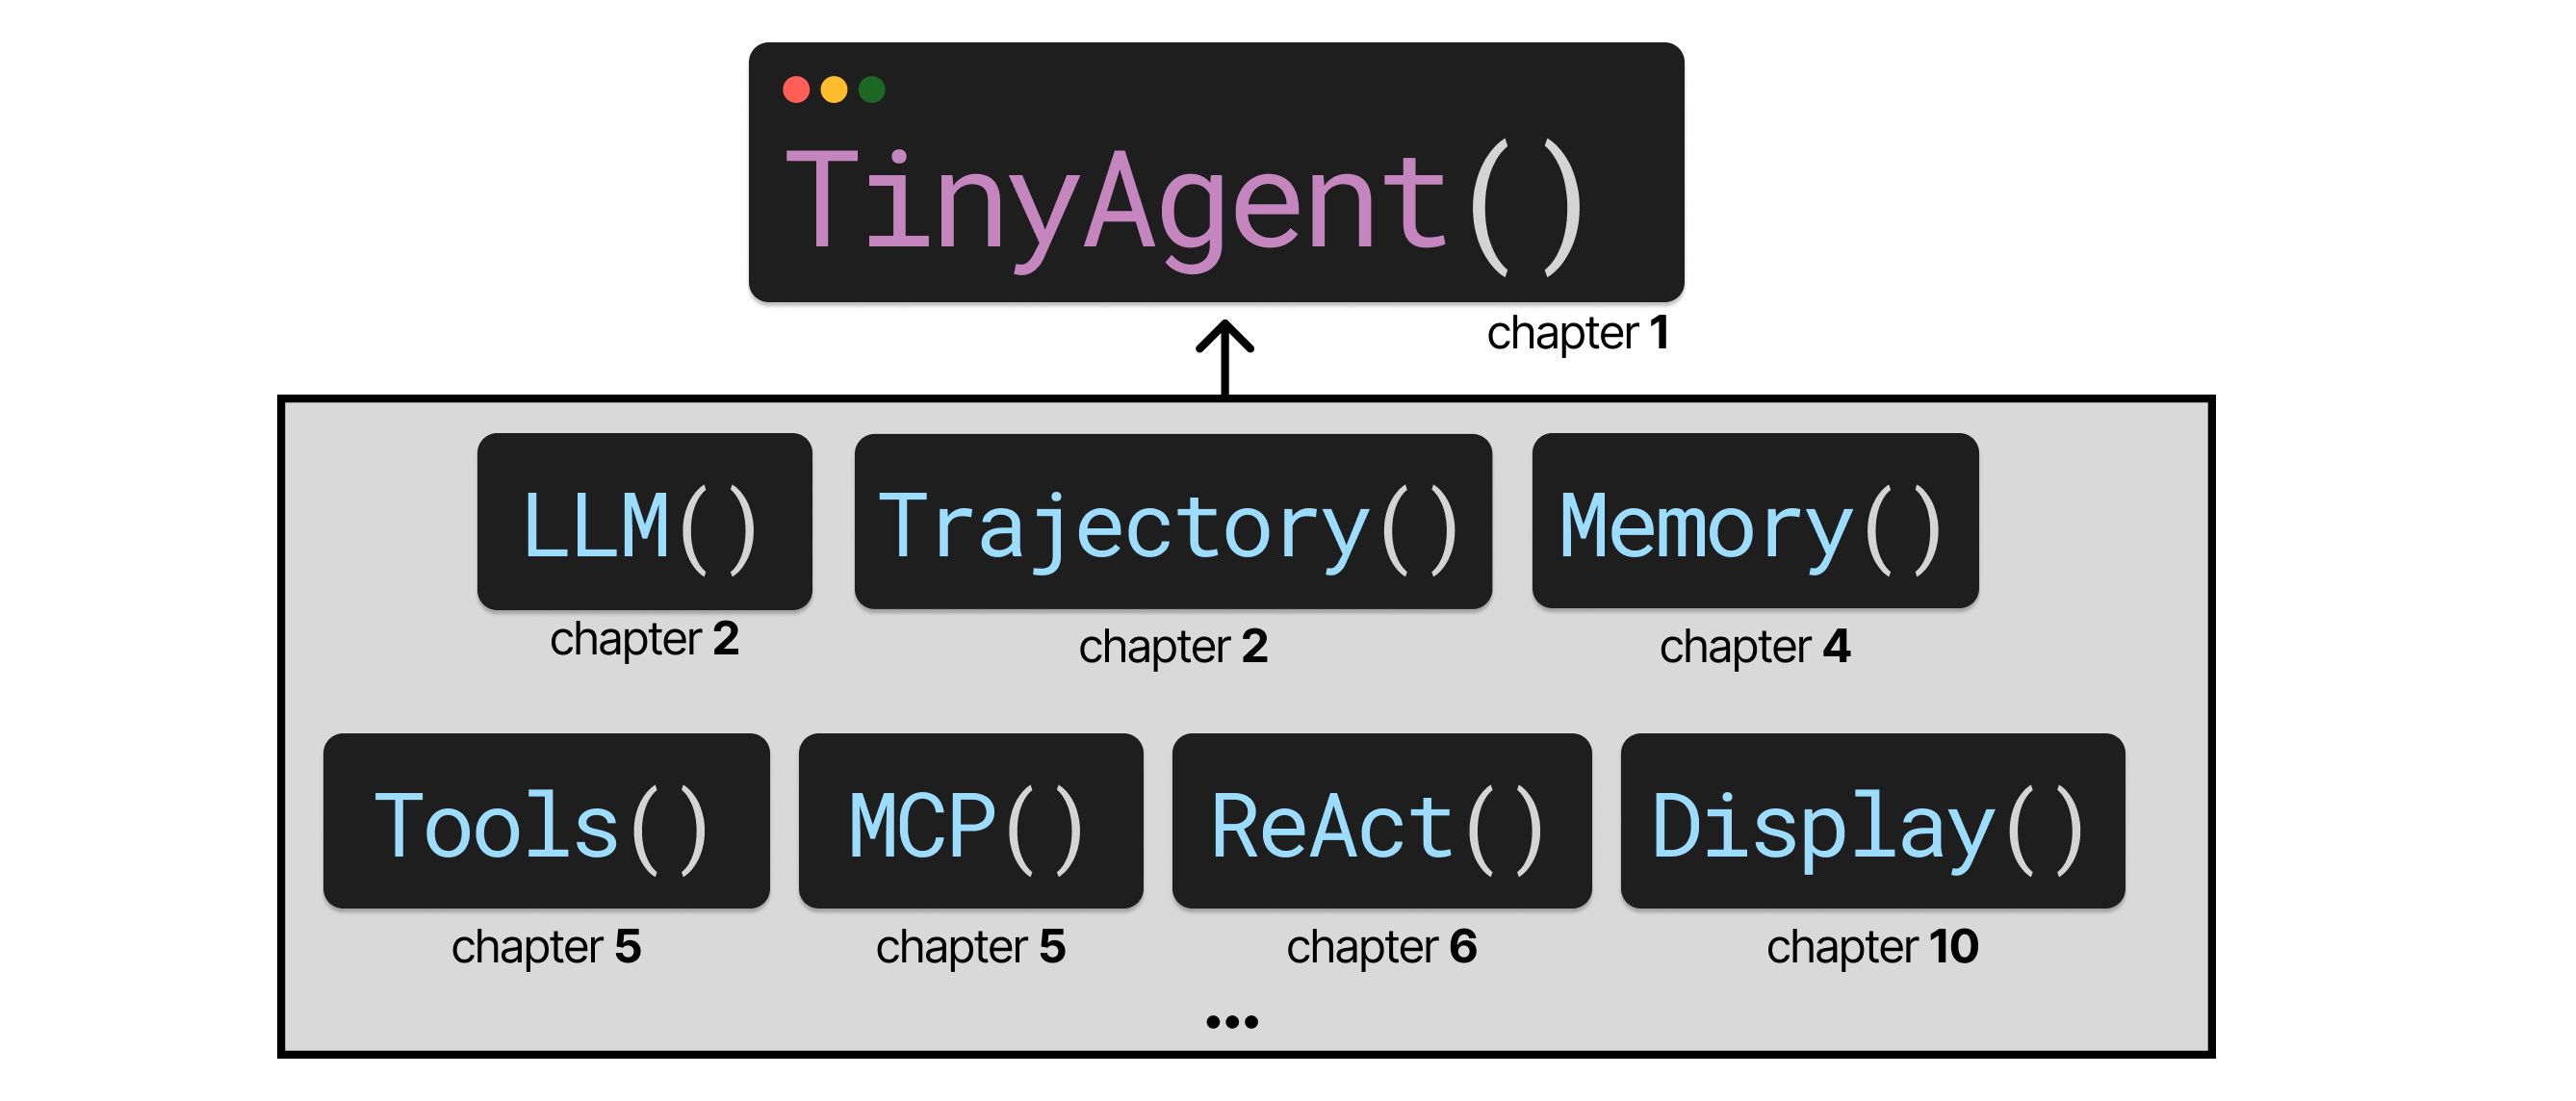
<br><span style="color:#6E6E6E; font-size:90%"><i>The TinyAgent you build across the course, one module per chapter. An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
class TinyAgent:
    """A minimal, modular, and educational agent framework."""

    def __init__(self):
        self.llm = None      # LLMs module: add the brain
        self.memory = None   # Memory module: remember the conversation
        self.tools = None    # Tools module: act on the world
        self.planner = None  # Planning module: multi-step reasoning

    def run(self, task: str) -> str:
        """Run the agent on a task."""
        return self._step(task)

    def _step(self, task: str) -> str:
        """Perform a single step."""
        # Placeholder - will be implemented in later modules
        return f"Received: {task}"

    def _execute_action(self, action: str) -> str:
        """Execute a tool action."""
        # Placeholder - will be implemented in later modules
        return f"Executed action: {action}"

Now run it. Because it has no brain, it just **parrots** your question straight back.

In [ ]:
agent = TinyAgent()
print(agent.run('What is 2 + 2?'))
# Expected output:  Received: What is 2 + 2?

That is the whole point: a structure with no LLM is **not** an agent yet. 
Next we give it a brain.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 2 — First contact with the brain (Gemini)</h2>
</div>

Before wiring Gemini into the agent, let's make one direct call so you can see the mechanics: **text in, text out**.

We call the model with the Google SDK. (Your `Practical/Google_AI_Studio` lab shows the same client in more depth.)

<div align="center">
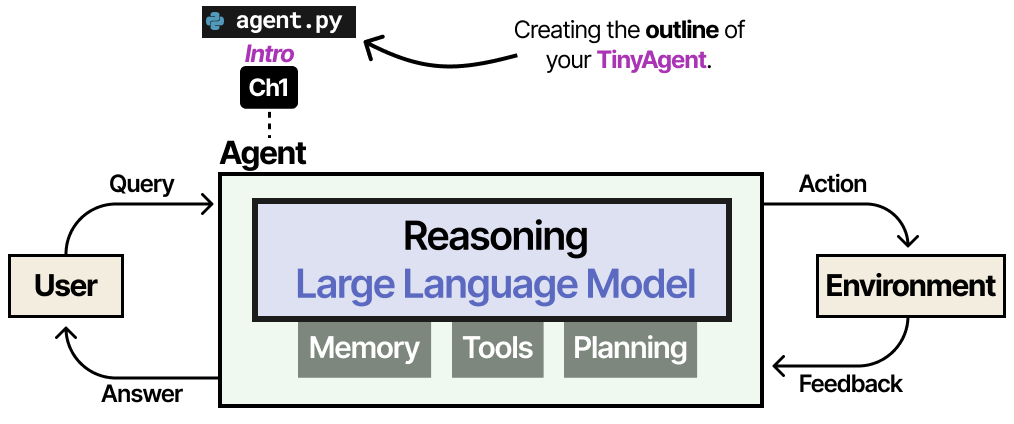
<br><span style="color:#6E6E6E; font-size:90%"><i>The anatomy of an agent: a reasoning LLM plus memory, tools, and planning. An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
from google import genai

client = genai.Client()  # reads GEMINI_API_KEY from the environment

def ask_gemini(prompt: str) -> str:
    """Send a single prompt to Gemini and return the text answer."""
    try:
        resp = client.models.generate_content(model=MODEL, contents=prompt)
        return resp.text
    except Exception as e:
        # Common causes: wrong/disabled MODEL name, missing key, or no quota.
        return f"[Call failed: {type(e).__name__}: {e}]"

print(ask_gemini('In one sentence, what is an AI agent?'))

The model returned **text** — nothing more. On its own it has no memory of past turns and cannot take actions. 

**Aside — the 'from scratch' view.** The book's `TinyAgent` talks to a model over a plain HTTP endpoint (the OpenAI-compatible API), which Gemini also exposes. You do not need it today, but here is what that looks like, so you can see there is no magic — just a web request:

In [ ]:
# OPTIONAL — the same idea using the OpenAI-compatible endpoint that the book's TinyAgent uses.
# This shows that an 'LLM call' is just an HTTP request with messages in and a message out.
from openai import OpenAI

def ask_gemini_openai(prompt: str) -> str:
    try:
        oai = OpenAI(
            api_key=os.environ['GEMINI_API_KEY'],
            base_url='https://generativelanguage.googleapis.com/v1beta/openai/',
        )
        r = oai.chat.completions.create(
            model=MODEL,
            messages=[{'role': 'user', 'content': prompt}],
        )
        return r.choices[0].message.content
    except Exception as e:
        return f"[Call failed: {type(e).__name__}: {e}]"

print(ask_gemini_openai('Say hello in five words.'))

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 3 — Give the skeleton a brain</h2>
</div>

Now we connect the brain to the agent: instead of echoing the task, `_step` asks Gemini and returns the answer. 
This is the first real upgrade to our `TinyAgent` — in the next module we will structure it more carefully, but the idea is already here.

In [ ]:
class TinyAgentWithBrain(TinyAgent):
    """TinyAgent whose single step now calls an LLM (the brain)."""

    def __init__(self, system_prompt: str = 'You are a helpful assistant.'):
        super().__init__()
        self.system_prompt = system_prompt

    def _step(self, task: str) -> str:
        # THOUGHT: send the task to the brain and return its answer.
        full_prompt = f'{self.system_prompt}\n\nUser: {task}'
        return ask_gemini(full_prompt)

brain_agent = TinyAgentWithBrain()
print(brain_agent.run('What is 2 + 2? Explain in one short sentence.'))

It no longer parrots — it **answers**. But it is still **stateless**: ask a follow-up and it will have forgotten the previous turn. Try it:

In [ ]:
print(brain_agent.run('My name is Sara.'))
print(brain_agent.run('What is my name?'))  # It will not know - no memory yet.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Exercise</h2>
</div>

**Task A.** Create a `TinyAgentWithBrain` whose `system_prompt` turns it into a **study-planning assistant** (for example: *"You are a study planner. Given a topic, reply with a 3-step study plan."*). Then run it on the topic *"learn the basics of AI agents"*.

**Task B (think, no code).** In the cell comments, write **which augmentation** (memory, tools, or planning) is missing that stops this agent from remembering your name across turns.

Fill in the `# YOUR CODE HERE` lines, then check your work against the solution below.

In [ ]:
# YOUR CODE HERE
# Task A: build a study-planner agent and run it.
# planner_agent = TinyAgentWithBrain(system_prompt=...)
# print(planner_agent.run(...))

# Task B (answer in a comment): which augmentation is missing for multi-turn memory?
# Answer: ...

**Solution** (try it yourself first):

In [ ]:
# --- Solution ---
# Task A
planner_agent = TinyAgentWithBrain(
    system_prompt='You are a study planner. Given a topic, reply with a clear 3-step study plan.'
)
print(planner_agent.run('learn the basics of AI agents'))

# Task B
# The missing augmentation is MEMORY. Each run() sends only the current task to the model,
# so nothing from earlier turns is included in the prompt. We add a Memory module in the
# Memory lab, which keeps the conversation history and passes it back to the brain.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Summary and what we built</h2>
</div>

Today you:
- Built the `TinyAgent` **skeleton** — structure only, no brain (it echoed your input).
- Made your first **Gemini** call and saw an LLM is just *text in, text out*.
- Wired the brain into the agent so it **answers** — but it is still **stateless**.

```
TinyAgent/
  agent.py        <- the skeleton you built (plus a first brain)
```

**Next module (LLMs):** we structure the brain properly as an `llm.py` module and look at how LLMs actually work. Later modules add **memory**, **tools**, and **planning** — the pieces that turn this into a real agent.

**Further reading:** *An Illustrated Guide to AI Agents*, Chapter 1 (Introduction).